# 01 — Đọc & Xử lý dữ liệu
**Bài toán:** Hiệu suất giao hàng ảnh hưởng thế nào đến điểm review (Olist, Brazil 2016–2018).

Input: bảng `fact_orders` trong MySQL (tạo bởi `sql/03_build_mart.sql`, 1 dòng / order).
Output: `output/fact_orders_clean.csv` (toàn bộ order, có cờ `in_scope`) dùng cho EDA, What-if và Power BI.

## 1. Kết nối database & đọc dữ liệu

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils.config import DB_CONFIG
from utils.db import *
from utils.cleaning import *
from utils.outlier import *
from utils.stats import *

In [2]:
engine = make_engine(DB_CONFIG)
test_connection(engine)

Connected — MySQL 8.0.46


In [3]:
query = "SELECT * FROM fact_orders"
df = load_main_dataset(query, engine)
df.shape

(99441, 38)

In [4]:
# fact_orders rỗng -> dữ liệu chưa được nạp vào MySQL; dừng sớm thay vì lỗi khó hiểu ở các cell sau
if df.empty:
    raise ValueError(
        "fact_orders đang rỗng. Chạy lại từ thư mục capstone-project:\n"
        "  mysql --local-infile=1 -uroot -p < sql/02_load_data.sql\n"
        "  mysql -uroot -p < sql/03_build_mart.sql"
    )

In [5]:
df.head()

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,...,seller_lng,payment_value,payment_type,payment_installments,n_payments,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,...,-44.127492,72.19,credit_card,2.0,1.0,5.0,NaN,"Perfeito, produto entregue antes do combinado.",2017-09-21,2017-09-22 10:57:03
1,00018f77f2f0320c557190d7a144bdd3,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,...,-46.518565,259.83,credit_card,3.0,1.0,4.0,NaN,NaN,2017-05-13,2017-05-15 11:34:13
2,000229ec398224ef6ca0657da4fc703e,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,...,-46.171124,216.87,credit_card,5.0,1.0,5.0,NaN,Chegou antes do prazo previsto e o produto sur...,2018-01-23,2018-01-23 16:06:31
3,00024acbcdf0a6daa1e931b038114c75,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,...,-47.387359,25.78,credit_card,2.0,1.0,4.0,NaN,NaN,2018-08-15,2018-08-15 16:39:01
4,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,...,-53.135873,218.04,credit_card,3.0,1.0,5.0,NaN,Gostei pois veio no prazo determinado .,2017-03-02,2017-03-03 10:54:59


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 38 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   order_status                   99441 non-null  str           
 2   order_purchase_timestamp       99441 non-null  datetime64[us]
 3   order_approved_at              99281 non-null  datetime64[us]
 4   order_delivered_carrier_date   97658 non-null  datetime64[us]
 5   order_delivered_customer_date  96476 non-null  datetime64[us]
 6   order_estimated_delivery_date  99441 non-null  datetime64[us]
 7   customer_unique_id             99441 non-null  str           
 8   customer_zip_code_prefix       99441 non-null  str           
 9   customer_city                  99441 non-null  str           
 10  customer_state                 99441 non-null  str           
 11  customer_lat              

## 2. Kiểu dữ liệu

In [7]:
# Cột ngày đã là datetime (pymysql). Zip code phải giữ dạng chuỗi (có số 0 ở đầu).
date_cols = [c for c in df.columns if "date" in c or "timestamp" in c or c == "order_approved_at"]
df[date_cols].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
shipping_limit_date              datetime64[us]
review_creation_date             datetime64[us]
review_answer_timestamp          datetime64[us]
dtype: object

In [8]:
mb_before = df.memory_usage(deep=True).sum() / 1024**2
print(f"Before is {mb_before:.2f} MB")

if df.empty:
    print("Skipping dtype optimization: df contains no rows.")
else:
    df = optimize_dtypes(df)

mb_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"After is {mb_after:.2f} MB")

Before is 106.30 MB


After is 38.15 MB


In [9]:
# optimize_dtypes ép float64 -> float32; tiền tệ giữ float64 để tổng không lệch
money_cols = ["total_price", "total_freight", "payment_value"]
df[money_cols] = df[money_cols].astype("float64")
df.dtypes

order_id                                    str
order_status                           category
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
customer_unique_id                          str
customer_zip_code_prefix               category
customer_city                          category
customer_state                         category
customer_lat                            float32
customer_lng                            float32
n_items                                 float32
n_products                              float32
n_sellers                               float32
total_price                             float64
total_freight                           float64
shipping_limit_date              datetime64[us]
main_product_id                        category
main_category                          c

## 3. Giá trị NULL

In [10]:
qr = quality_report(df)
qr[qr["missing"] > 0]

,dtype,missing,missing%,unique,sample
column,,,,,
review_comment_title,category,87893,88.4,4524,Boa
review_comment_message,category,58675,59.0,36059,"Perfeito, produto entregue antes do combinado."
order_delivered_customer_date,datetime64[us],2965,3.0,95664,2017-09-20 23:43:48
product_photos_qty,float32,2190,2.2,19,4.0
order_delivered_carrier_date,datetime64[us],1783,1.8,81018,2017-09-19 18:34:16
seller_lng,float32,991,1.0,2227,-44.127491
seller_lat,float32,991,1.0,2233,-22.496952
seller_city,category,775,0.8,611,volta redonda
product_weight_g,float32,791,0.8,2194,650.0


**Nhận xét & cách xử lý NULL**

| Cột | Nguyên nhân | Xử lý |
|---|---|---|
| `review_comment_title/message` | Khách chỉ chấm sao, không viết | Giữ NULL, tạo cờ `has_comment` |
| `order_delivered_customer_date` | Đơn chưa giao / huỷ | Giữ để thống kê; loại khỏi phạm vi phân tích |
| `order_delivered_carrier_date`, `order_approved_at` | Đơn chưa duyệt / chưa giao cho vận chuyển | Giữ NULL |
| `review_score` (768) | Order không có review | Loại khỏi phạm vi phân tích (không có target) |
| `n_items`, `main_category`, seller... (775) | Order không có item (chủ yếu huỷ/unavailable) | Loại khỏi phạm vi phân tích |
| `customer_lat/lng`, `seller_lat/lng` | Zip prefix không có trong bảng geolocation | `distance_km` = NULL; fill median khi đưa vào model |
| `product_weight_g`, `product_photos_qty` | Sản phẩm thiếu thông tin | Fill median khi đưa vào model |

In [11]:
df.groupby(df["n_items"].isna())["order_status"].value_counts().unstack(0)

n_items,False,True
order_status,,
approved,2,0
canceled,461,164
created,0,5
delivered,96478,0
invoiced,312,2
processing,301,0
shipped,1106,1
unavailable,6,603


In [12]:
df["has_comment"] = df["review_comment_message"].notna().astype("int8")

## 4. Trùng lặp

In [13]:
check_duplicates(df, ["order_id"])

Full duplicates    : OK
Key duplicates ['order_id']: OK


Trùng lặp review (1 order nhiều review, 1 review_id gắn nhiều order) đã xử lý ở SQL: giữ review mới nhất mỗi order (`ROW_NUMBER()` theo `review_answer_timestamp`).

## 5. Lỗi logic

In [14]:
checks = {
    "Delivered before purchase"   : df["order_delivered_customer_date"] < df["order_purchase_timestamp"],
    "Approved before purchase"    : df["order_approved_at"] < df["order_purchase_timestamp"],
    "Carrier before purchase"     : df["order_delivered_carrier_date"] < df["order_purchase_timestamp"],
    "Delivered before carrier"    : df["order_delivered_customer_date"] < df["order_delivered_carrier_date"],
    "Estimated before purchase"   : df["order_estimated_delivery_date"] < df["order_purchase_timestamp"],
    "Price <= 0"                  : df["total_price"] <= 0,
    "Freight < 0"                 : df["total_freight"] < 0,
    "Review score not in 1..5"    : ~df["review_score"].isin([1, 2, 3, 4, 5]) & df["review_score"].notna(),
    "Delivered status, no date"   : (df["order_status"] == "delivered") & df["order_delivered_customer_date"].isna(),
}
check_data_issues(df, checks)

Delivered before purchase          : OK
Approved before purchase           : OK
Carrier before purchase            : 166 rows
Delivered before carrier           : 23 rows
Estimated before purchase          : OK
Price <= 0                         : OK
Freight < 0                        : OK
Review score not in 1..5           : OK
Delivered status, no date          : 8 rows


**Xử lý:** ngày giao cho đơn vị vận chuyển (`order_delivered_carrier_date`) sai logic ở vài trăm đơn → chỉ ảnh hưởng `handling_days`, nên đặt `handling_days = NULL` cho các đơn này, giữ lại đơn (ngày giao cho khách vẫn hợp lệ).

In [15]:
carrier_issue = checks["Carrier before purchase"] | checks["Delivered before carrier"]
df["carrier_date_issue"] = carrier_issue.astype("int8")
df["carrier_date_issue"].sum()

np.int64(189)

## 6. Feature engineering

In [16]:
def days_between(end, start):
    return (end - start).dt.total_seconds() / 86400

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# Thời gian
df["delivery_days"]  = days_between(df["order_delivered_customer_date"], df["order_purchase_timestamp"])
df["estimated_days"] = days_between(df["order_estimated_delivery_date"], df["order_purchase_timestamp"])
df["handling_days"]  = days_between(df["order_delivered_carrier_date"], df["order_purchase_timestamp"])
df.loc[df["carrier_date_issue"] == 1, "handling_days"] = np.nan

# Ngày dự kiến chỉ có phần ngày (00:00) -> so sánh theo ngày lịch
df["delay_days"] = (df["order_delivered_customer_date"].dt.normalize()
                    - df["order_estimated_delivery_date"].dt.normalize()).dt.days
df["is_late"] = np.where(df["delay_days"].notna(), (df["delay_days"] > 0).astype(float), np.nan)

df["delay_bucket"] = pd.cut(
    df["delay_days"],
    bins=[-np.inf, -8, 0, 3, 7, np.inf],
    labels=["Early >7d", "Early/On time (0-7d)", "Late 1-3d", "Late 4-7d", "Late >7d"],
)

# Chi phí & địa lý
df["freight_ratio"] = df["total_freight"] / df["total_price"]
df["distance_km"]   = haversine_km(df["customer_lat"], df["customer_lng"],
                                   df["seller_lat"], df["seller_lng"])
df["same_state"]    = np.where(df["seller_state"].notna(),
                               (df["customer_state"].astype(str) == df["seller_state"].astype(str)).astype(float),
                               np.nan)

# Target
df["bad_review"] = np.where(df["review_score"].notna(), (df["review_score"] <= 2).astype(float), np.nan)

# Thời gian đặt hàng
df = add_datetime_features(df, "order_purchase_timestamp")
df["year_month"] = df["order_purchase_timestamp"].dt.strftime("%Y-%m")

df[["delivery_days", "estimated_days", "handling_days", "delay_days", "is_late",
    "freight_ratio", "distance_km", "same_state", "bad_review"]].describe().round(2)

,delivery_days,estimated_days,handling_days,delay_days,is_late,freight_ratio,distance_km,same_state,bad_review
count,96476.00,99441.00,97469.00,96476.00,96476.00,98666.00,98177.00,98666.00,98673.00
mean,12.56,23.77,3.24,-11.88,0.07,0.31,601.64,0.36,0.15
std,9.55,8.83,3.57,10.18,0.25,0.31,595.13,0.48,0.35
min,0.53,1.65,0.00,-147.00,0.00,0.00,0.00,0.00,0.00
25%,6.77,18.33,1.13,-17.00,0.00,0.13,185.92,0.00,0.00
50%,10.22,23.24,2.21,-12.00,0.00,0.22,433.78,0.00,0.00
75%,15.72,28.42,4.07,-7.00,0.00,0.38,799.37,1.00,0.00
max,209.63,155.14,125.78,188.00,1.00,21.45,8677.91,1.00,1.00


## 7. Phạm vi phân tích
- Chỉ đơn `delivered` có ngày giao thực tế và có review (cần cả biến giao hàng lẫn target).
- Bỏ 2016 và 09–10/2018: rất ít đơn (vài trăm), không đại diện → giữ 01/2017 – 08/2018.

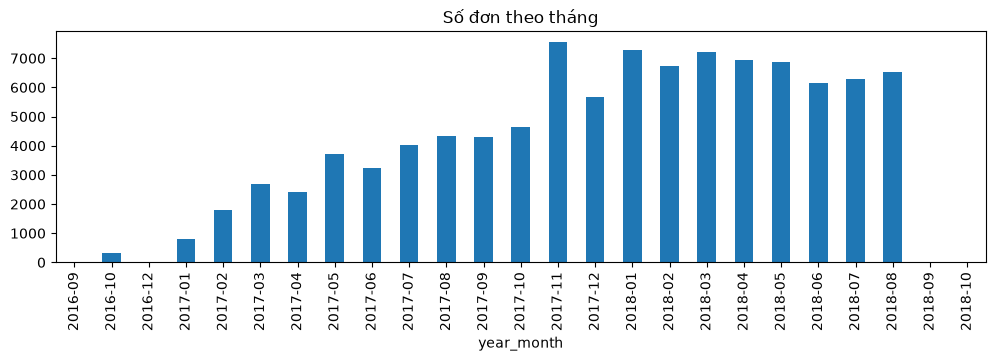

In [17]:
df.groupby("year_month").size().plot(kind="bar", figsize=(12, 3), title="Số đơn theo tháng")
plt.show()

In [18]:
df["in_scope"] = (
    (df["order_status"] == "delivered")
    & df["order_delivered_customer_date"].notna()
    & df["review_score"].notna()
    & df["n_items"].notna()
    & df["order_purchase_timestamp"].between("2017-01-01", "2018-08-31 23:59:59")
).astype("int8")

print(f"Tổng order      : {len(df):,}")
print(f"Trong phạm vi   : {df['in_scope'].sum():,} ({df['in_scope'].mean():.1%})")

Tổng order      : 99,441
Trong phạm vi   : 95,560 (96.1%)


## 8. Ngoại lai

In [19]:
scope = df[df["in_scope"] == 1]
num_cols = ["total_price", "total_freight", "freight_ratio", "delivery_days",
            "delay_days", "distance_km", "n_items", "product_weight_g"]
outlier_summary(scope, num_cols)

column                      lower      upper    n_out    pct
------------------------------------------------------------
total_price                -110.1      305.9    7,562   7.9%
total_freight                -1.4       39.2    9,599  10.0%
freight_ratio                -0.2        0.8    6,336   6.6%
delivery_days                -6.6       28.9    4,909   5.1%
delay_days                  -32.0        8.0    4,026   4.2%
distance_km                -732.9    1,717.0    7,331   7.7%
n_items                       1.0        1.0    9,499   9.9%
product_weight_g         -1,969.5    4,082.5   13,646  14.3%


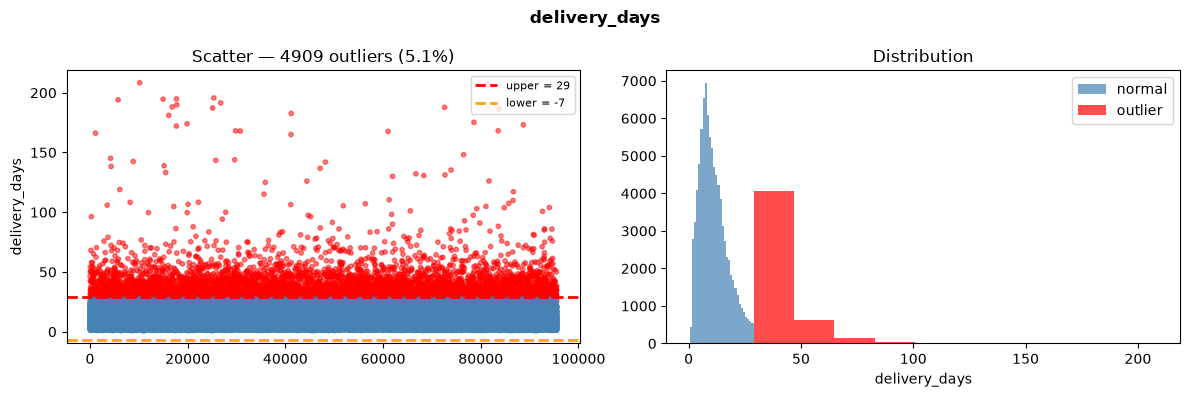

In [20]:
plot_outlier(scope, "delivery_days")

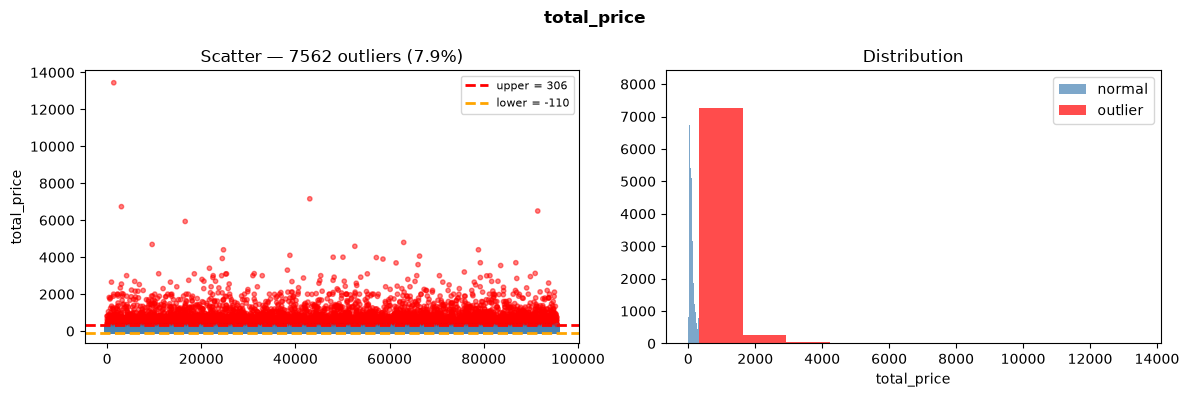

In [21]:
plot_outlier(scope, "total_price")

In [22]:
scope.nlargest(5, "delivery_days")[["order_id", "order_purchase_timestamp",
    "order_delivered_customer_date", "order_estimated_delivery_date",
    "delivery_days", "delay_days", "review_score"]]

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,review_score
10585,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.351759,188.0,2.0
26387,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.634016,165.0,1.0
18444,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,194.850174,155.0,4.0
15574,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.633611,166.0,1.0
5983,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.049583,161.0,4.0


**Quyết định xử lý ngoại lai**
- `total_price`, `total_freight`: phân phối lệch phải do có hàng giá trị cao (đồ điện tử, nội thất) — là giao dịch thật → **giữ nguyên**, dùng median khi tóm tắt.
- `delivery_days`, `delay_days`: các đơn giao rất trễ là **chính đối tượng cần nghiên cứu** → giữ nguyên trong EDA. Khi đưa vào model, `delay_days` được clip (xem notebook 03) để hệ số không bị vài điểm cực trị chi phối.
- Không xoá dòng nào vì ngoại lai.

## 9. Xuất dữ liệu sạch

In [23]:
drop_cols = ["review_comment_title"]   # 88% NULL, không dùng
out = df.drop(columns=drop_cols)
out.to_csv("../output/fact_orders_clean.csv", index=False)
print(out.shape)

(99441, 54)


In [24]:
qr_after = quality_report(out[out["in_scope"] == 1])
qr_after[qr_after["missing"] > 0]

,dtype,missing,missing%,unique,sample
column,,,,,
review_comment_message,category,56856,59.5,34167,"Perfeito, produto entregue antes do combinado."
product_photos_qty,float32,1347,1.4,19,4.0
distance_km,float32,475,0.5,89346,301.504669
customer_lng,float32,263,0.3,14611,-41.309631
customer_lat,float32,263,0.3,14640,-21.762775
seller_lat,float32,213,0.2,2139,-22.496952
handling_days,float64,184,0.2,86425,6.399468
seller_lng,float32,213,0.2,2134,-44.127491
order_approved_at,datetime64[us],14,0.0,87456,2017-09-13 09:45:35


Các NULL còn lại trong phạm vi phân tích là có chủ ý: comment trống, `handling_days` (ngày vận chuyển lỗi), toạ độ thiếu (→ `distance_km`, `same_state`), thông tin sản phẩm thiếu.